In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(10)

In [110]:
class sigmoid():
    def __init__(self):
        self.out = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.out = 1 / (1 + np.exp(-x))
        return self.out

    def backward(self, grad_output):
        # f'(x) = f(x) * (1 - f(x)) 
        return grad_output * self.out * (1 - self.out)

In [111]:
class relu():
    def __init__(self):
        self.input = None
        self.learning_rate = 0.01
        self.optymalizacja = None
        self.wspolczynnik = 0.9

    def forward(self, x):
        self.input = x
        return np.maximum(0, x)
    
    def backward(self, grad_output):
        grad_input = grad_output.copy()
        grad_input[self.input <= 0] = 0
        return grad_input

In [112]:
class warstwa_liniowa():
    def __init__(self, liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych, inicjalizacja):
        self.liczba_neuronow_wejsciowych = liczba_neuronow_wejsciowych
        self.liczba_neuronow_wyjsciowych = liczba_neuronow_wyjsciowych

        self.wspolczynnik = 0.9

        # inicjalizacja wag za pomocą Xaviera
        if inicjalizacja == 'xavier':
            a = -np.sqrt(6/(liczba_neuronow_wejsciowych+liczba_neuronow_wyjsciowych))
            b = -a
        # inicjalizacja wag za pomocą He
        elif inicjalizacja == 'he':
            a = -np.sqrt(6/liczba_neuronow_wejsciowych)
            b = -a
        else:
            a = 0
            b = 1
        self.wagi = np.random.uniform(a, b, (liczba_neuronow_wejsciowych, liczba_neuronow_wyjsciowych))
        self.bias = np.zeros((1, liczba_neuronow_wyjsciowych))

        self.input = None
        self.grad_wagi = None
        self.grad_bias = None

        self.learning_rate = 0.01

        self.rmsprop_wagi = np.zeros_like(self.wagi)
        self.rmsprop_bias = np.zeros_like(self.bias)
        
        self.moment_wagi = np.zeros_like(self.wagi)
        self.moment_bias = np.zeros_like(self.bias)

    def forward(self, x):
        # x - neurony wejsciowe, wektor o dlugosci = liczba_neuronow_wejsciowych
        self.input = x
        return np.dot(x, self.wagi) + self.bias
    
    def backward(self, grad_output):
        # L - funkcja straty
        # grad_output = dL/dY
        # input = x
        
        N = len(self.input)

        # dL/dX
        grad_input = np.dot(grad_output, self.wagi.T)
        # dL/dW
        self.grad_wagi = np.dot(self.input.T, grad_output) / N
        # dL/db
        self.grad_bias = np.sum(grad_output, axis=0, keepdims=True) / N

        return grad_input
    
    def update(self):
        self.wagi -= self.learning_rate * self.grad_wagi
        self.bias -= self.learning_rate * self.grad_bias

    def update_moment(self):
        self.moment_wagi = self.wspolczynnik * self.moment_wagi + self.learning_rate * self.grad_wagi
        self.moment_bias = self.wspolczynnik * self.moment_bias + self.learning_rate * self.grad_bias
        self.wagi -= self.moment_wagi
        self.bias -= self.moment_bias

    def update_RMSProp(self):
        eps = 1e-8
        self.rmsprop_wagi = self.wspolczynnik * self.rmsprop_wagi + (1 - self.wspolczynnik) * (self.grad_wagi ** 2)
        self.rmsprop_bias = self.wspolczynnik * self.rmsprop_bias + (1 - self.wspolczynnik) * (self.grad_bias ** 2)
        self.wagi -= (self.learning_rate / np.sqrt(self.rmsprop_wagi + eps)) * self.grad_wagi
        self.bias -= (self.learning_rate / np.sqrt(self.rmsprop_bias + eps)) * self.grad_bias

In [113]:
class MLP():
    def __init__(self, warstwy, learning_rate, optymalizacja=None, wspolczynnik=0.9):
        self.warstwy = warstwy # lista obiektów warstwa_liniowa i funkcji aktywacji
        self.learning_rate = learning_rate
        self.optymalizacja = optymalizacja
        self.wspolczynnik = wspolczynnik
        for warstwa in self.warstwy:
            warstwa.learning_rate = self.learning_rate
            warstwa.wspolczynnik = self.wspolczynnik

    def forward(self, x):
        for warstwa in self.warstwy:
            x = warstwa.forward(x)
        return x
    
    def backward(self, grad_output):
        for warstwa in reversed(self.warstwy):
            grad_output = warstwa.backward(grad_output)
        return grad_output
    
    def update(self):
        for warstwa in self.warstwy:
            if self.optymalizacja == 'RMSProp' and hasattr(warstwa, 'update_RMSProp'):
                warstwa.update_RMSProp()
            elif self.optymalizacja == 'moment' and hasattr(warstwa, 'update_moment'):
                warstwa.update_moment()
            elif hasattr(warstwa, 'update'):
                warstwa.update()

In [114]:
def wykresy(X_train, y_train, X_test, y_test, y_pred_train, y_pred_test, hist_mse, hist_wagi, epoki, test=False):
    if (test):
        # Wykres MSE
        plt.figure(figsize=(10, 4))
        plt.plot(range(epoki), hist_mse, color='red')
        plt.title('MSE')
        plt.xlabel('Epoka')
        plt.ylabel('Nieznormalizowane MSE')
        plt.yscale('log')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()

        # Wagi
        liczba_warstw = len(hist_wagi)
        if liczba_warstw > 0:
            fig, axes = plt.subplots(1, liczba_warstw, figsize=(5 * liczba_warstw, 5))
            
            if liczba_warstw == 1:
                axes = [axes]

            for numer_warstwy, (idx, historia) in enumerate(hist_wagi.items()):
                ax = axes[numer_warstwy]
                historia_np = np.array(historia)
                epoki_w_historii = historia_np.shape[0]
                wejscia = historia_np.shape[1]
                wyjscia = historia_np.shape[2]
                
                for wej in range(wejscia):
                    for wyj in range(wyjscia):
                        ax.plot(range(epoki_w_historii), historia_np[:, wej, wyj])
                
                ax.set_title(f'Warstwa Liniowa {numer_warstwy + 1}')
                ax.set_xlabel('Epoka')
                ax.set_ylabel('Wartość wagi')
                    
            plt.tight_layout()
            plt.show()

    # Wykresy dopasowania
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Zbiór Treningowy
    ax1.scatter(X_train, y_train, color='blue', alpha=0.6, label='Prawdziwa wartość')
    ax1.scatter(X_train, y_pred_train, color='orange', alpha=0.6, label='Przewidziana wartość')
    ax1.set_title('Dopasowanie - Zbiór Treningowy')
    ax1.legend()

    # Zbiór Testowy
    ax2.scatter(X_test, y_test, color='blue', alpha=0.6, label='Prawdziwa wartość')
    ax2.scatter(X_test, y_pred_test, color='orange', alpha=0.6, label='Przewidziana wartość')
    ax2.set_title('Dopasowanie - Zbiór Testowy')
    ax2.legend()

    plt.tight_layout()
    plt.show()

In [115]:
def train(X_train, y_train, X_test, y_test, model, epoki, rozmiar_batcha, test=False, test_MSE=False):
    x_min = X_train.min(axis=0)
    x_max = X_train.max(axis=0)
    y_min = y_train.min(axis=0)
    y_max = y_train.max(axis=0)

    X_train_scaled = (X_train - x_min) / (x_max - x_min)
    y_train_scaled = (y_train - y_min) / (y_max - y_min)
    X_test_scaled = (X_test - x_min) / (x_max - x_min)
    y_test_scaled = (y_test - y_min) / (y_max - y_min)
    
    N = y_train.shape[0] 

    hist_wagi = {i: [] for i, w in enumerate(model.warstwy) if hasattr(w, 'wagi')}
    hist_mse = []

    for i in range(epoki):
        # Tasowanie danych
        indeksy = np.random.permutation(N)
        X_shuffled = X_train_scaled[indeksy]
        y_shuffled = y_train_scaled[indeksy]
        
        for start in range(0, N, rozmiar_batcha):
            koniec = start + rozmiar_batcha
            X_batch = X_shuffled[start:koniec]
            y_batch = y_shuffled[start:koniec]
            
            # Propagacja w przód, w tył i aktualizacja wag
            y_pred_batch = model.forward(X_batch)
            grad_output = y_pred_batch - y_batch
            model.backward(grad_output)
            model.update()

        # Zapis historii wag co epokę
        for idx, warstwa in enumerate(model.warstwy):
            if hasattr(warstwa, 'wagi'):
                hist_wagi[idx].append(warstwa.wagi.copy())
        
        # Obliczanie MSE TRENINGOWEGO co epokę dla wykresu błędu
        y_pred_all = model.forward(X_train_scaled)
        y_pred_unscaled = y_pred_all * (y_max - y_min) + y_min
        mse_treningowe = np.mean((y_train - y_pred_unscaled) ** 2)
        hist_mse.append(mse_treningowe)

        # Obliczanie i wyświetlanie MSE TESTOWEGO co 1000 epok
        if test and i % 1000 == 0:
            if test_MSE:
                # Puszczamy zbiór testowy przez model
                y_pred_test_scaled = model.forward(X_test_scaled)
                y_pred_test_unscaled = y_pred_test_scaled * (y_max - y_min) + y_min
                mse_testowe_krok = np.mean((y_test - y_pred_test_unscaled) ** 2)
                print(f"Krok {i:>5} | MSE Trening: {mse_treningowe:>8.4f} | MSE Test: {mse_testowe_krok:>8.4f}")
            else:
                print(f"Krok {i:>5} | MSE Trening: {mse_treningowe:>8.4f}")

    print("-" * 50)
    print(f"MSE treningowe FINALNE: {hist_mse[-1]}")

    y_pred_test_scaled = model.forward(X_test_scaled)
    y_pred_test = y_pred_test_scaled * (y_max - y_min) + y_min
    mse_test = np.mean((y_test - y_pred_test) ** 2)
    print(f"MSE testowe FINALNE: {mse_test}")

    # Rysowanie wykresów
    wykresy(X_train, y_train, X_test, y_test, y_pred_unscaled, y_pred_test, hist_mse, hist_wagi, epoki, test)

    return hist_mse

In [116]:
def wykres_mse(hist_brak, hist_rmsprop, hist_moment, zbior):
    plt.figure(figsize=(10, 5))

    plt.plot(hist_rmsprop, label='RMSProp', color='#17bd61', linewidth=2)
    plt.plot(hist_moment, label='Moment', color='#4ecdc4', linewidth=2)
    plt.plot(hist_brak, label='Brak', color='#ff6b6b', linewidth=2)
    plt.yscale('log')

    plt.title(f'Porównanie zbieżności MSE ({zbior})', fontsize=14)
    plt.xlabel('Epoka', fontsize=12)
    plt.ylabel('MSE (Trening)', fontsize=12)

    plt.legend(fontsize=12, loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

# Dane square large

In [117]:
square_large_test = pd.read_csv("mio1/regression/square-large-test.csv")
square_large_train = pd.read_csv("mio1/regression/square-large-training.csv")
X_train = square_large_train[['x']].to_numpy()
y_train = square_large_train[['y']].to_numpy()
X_test = square_large_test[['x']].to_numpy()
y_test = square_large_test[['y']].to_numpy()

In [118]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1)

Krok     0 | MSE Trening: 8970.5289
Krok  1000 | MSE Trening: 6508.0403
Krok  2000 | MSE Trening: 192.5131
Krok  3000 | MSE Trening:  71.8712
Krok  4000 | MSE Trening:  49.5826
Krok  5000 | MSE Trening:  35.9143
Krok  6000 | MSE Trening:  26.9887
Krok  7000 | MSE Trening:  20.4187
Krok  8000 | MSE Trening:  15.6523
Krok  9000 | MSE Trening:  12.1638
Krok 10000 | MSE Trening:   9.5040
Krok 11000 | MSE Trening:   7.3861
Krok 12000 | MSE Trening:   5.8470
Krok 13000 | MSE Trening:   4.6861
Krok 14000 | MSE Trening:   3.7629
Krok 15000 | MSE Trening:   3.0719
Krok 16000 | MSE Trening:   2.5342
Krok 17000 | MSE Trening:   2.1204
Krok 18000 | MSE Trening:   1.7924
Krok 19000 | MSE Trening:   1.5463
Krok 20000 | MSE Trening:   1.3409
Krok 21000 | MSE Trening:   1.1921
Krok 22000 | MSE Trening:   1.0603
Krok 23000 | MSE Trening:   0.9605
Krok 24000 | MSE Trening:   0.8731
Krok 25000 | MSE Trening:   0.8093
Krok 26000 | MSE Trening:   0.7522
Krok 27000 | MSE Trening:   0.7078
Krok 28000 | MSE T

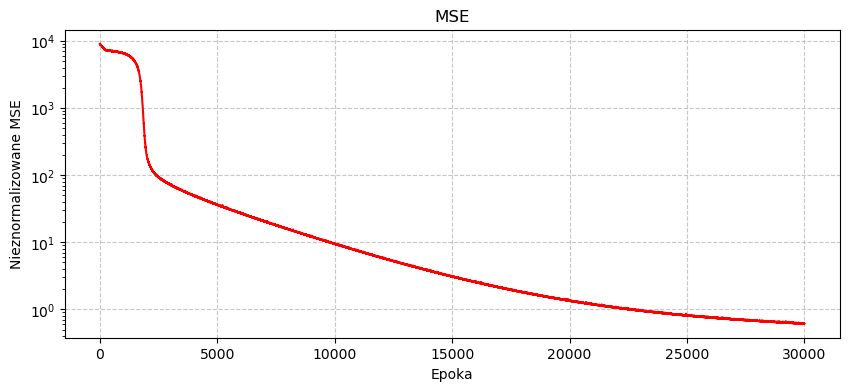

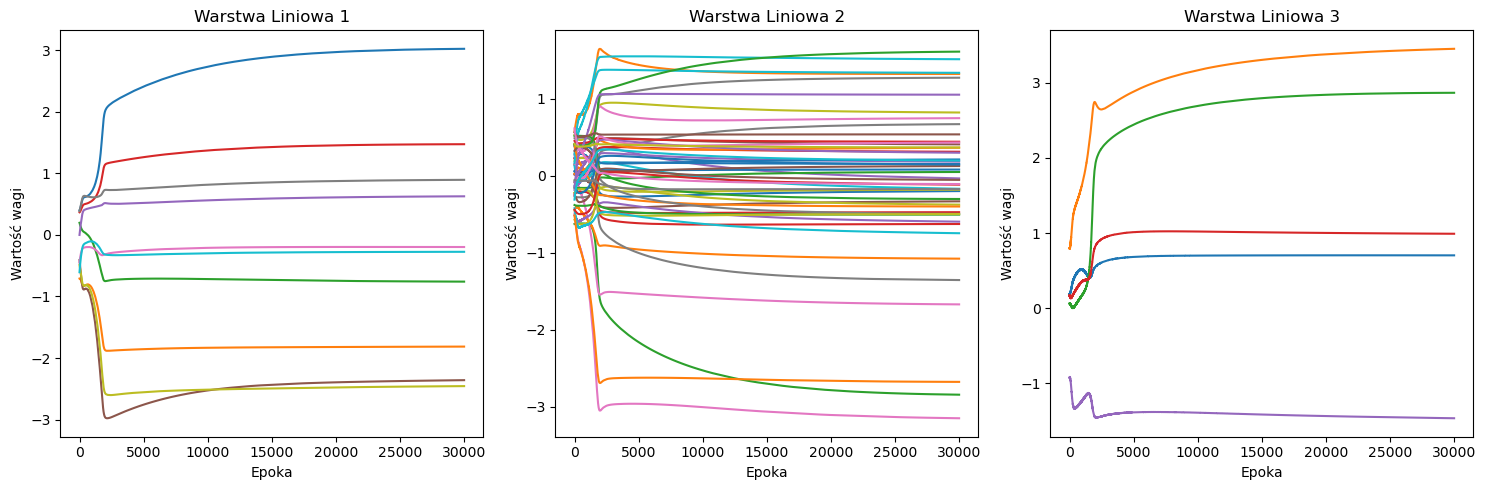

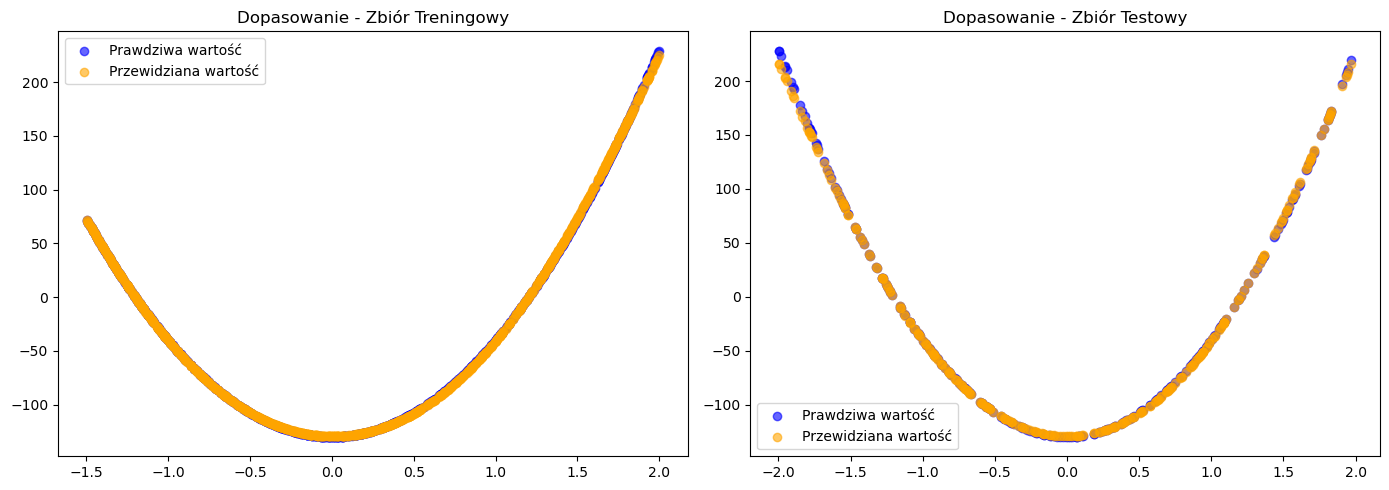

In [119]:
brak_1 = train(X_train, y_train, X_test, y_test, model, 30000, 64, True)

In [120]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.0001, optymalizacja='RMSProp', wspolczynnik=0.9)

Krok     0 | MSE Trening: 27549.1953
Krok  1000 | MSE Trening: 7197.0583
Krok  2000 | MSE Trening: 7015.8457
Krok  3000 | MSE Trening: 6798.1176
Krok  4000 | MSE Trening: 6096.8480
Krok  5000 | MSE Trening: 1028.9951
Krok  6000 | MSE Trening:  77.7080
Krok  7000 | MSE Trening:  23.5936
Krok  8000 | MSE Trening:   5.0360
Krok  9000 | MSE Trening:   1.5613
Krok 10000 | MSE Trening:   1.0341
Krok 11000 | MSE Trening:   0.8859
Krok 12000 | MSE Trening:   0.7745
Krok 13000 | MSE Trening:   0.7869
Krok 14000 | MSE Trening:   0.6356
Krok 15000 | MSE Trening:   0.5610
Krok 16000 | MSE Trening:   0.5256
Krok 17000 | MSE Trening:   0.4840
Krok 18000 | MSE Trening:   0.4392
Krok 19000 | MSE Trening:   0.5674
Krok 20000 | MSE Trening:   0.4435
Krok 21000 | MSE Trening:   0.3935
Krok 22000 | MSE Trening:   0.3593
Krok 23000 | MSE Trening:   0.3656
Krok 24000 | MSE Trening:   0.3489
Krok 25000 | MSE Trening:   0.3247
Krok 26000 | MSE Trening:   0.3745
Krok 27000 | MSE Trening:   0.3079
Krok 28000 | 

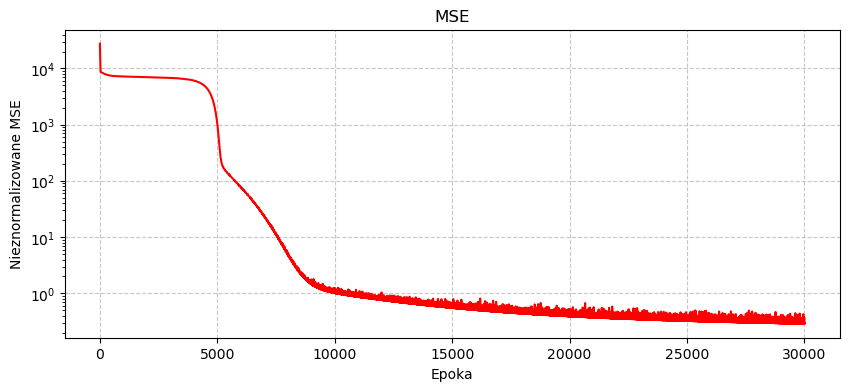

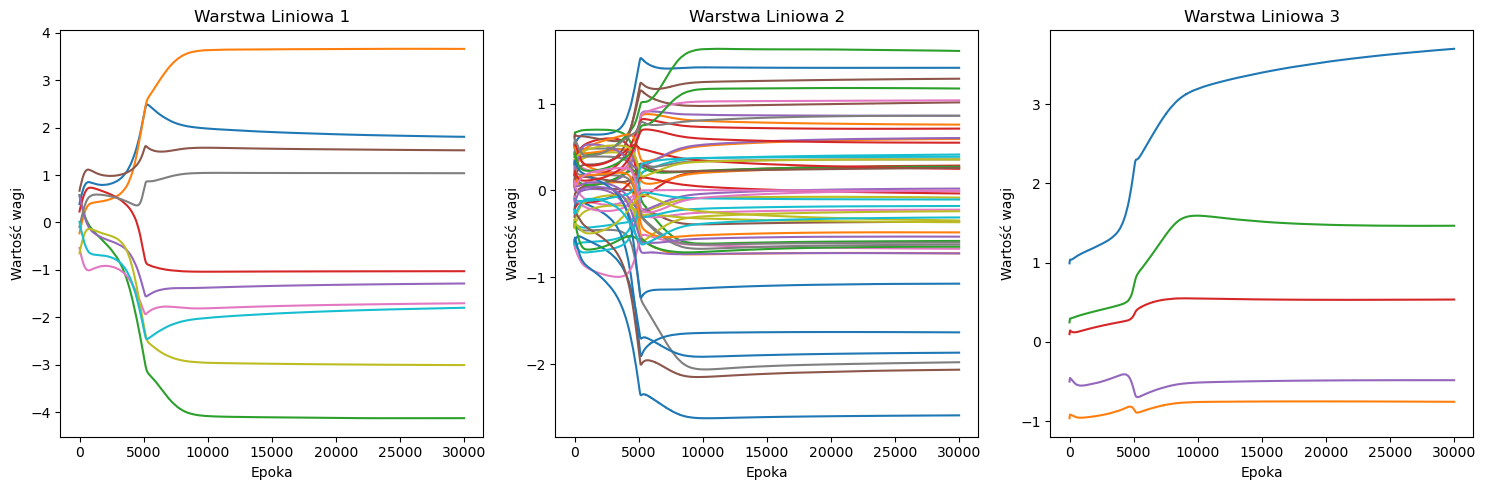

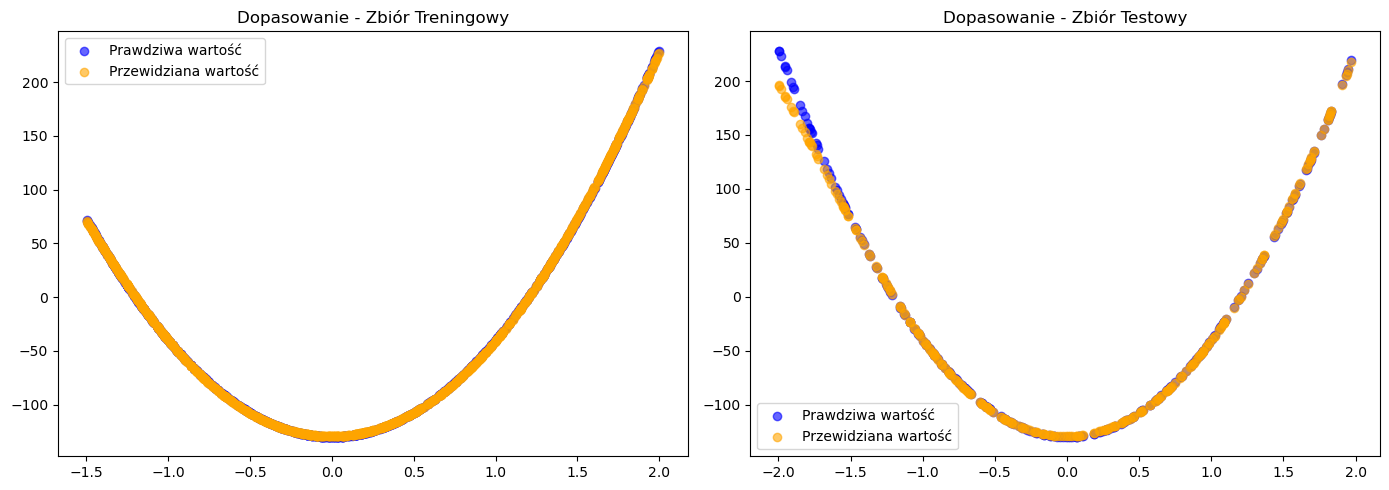

In [121]:
rmsprop_1 = train(X_train, y_train, X_test, y_test, model, 30000, 64, True)

In [122]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 5, 'xavier')
warstwa_3 = warstwa_liniowa(5, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | MSE Trening: 14191.4985
Krok  1000 | MSE Trening:  10.9982
Krok  2000 | MSE Trening:   1.0529
Krok  3000 | MSE Trening:   0.4066
Krok  4000 | MSE Trening:   0.2961
Krok  5000 | MSE Trening:   0.2635
Krok  6000 | MSE Trening:   0.2286
Krok  7000 | MSE Trening:   0.2096
Krok  8000 | MSE Trening:   0.2107
Krok  9000 | MSE Trening:   0.1954
Krok 10000 | MSE Trening:   0.1720
Krok 11000 | MSE Trening:   0.1739
Krok 12000 | MSE Trening:   0.1514
Krok 13000 | MSE Trening:   0.1528
Krok 14000 | MSE Trening:   0.1367
Krok 15000 | MSE Trening:   0.1319
Krok 16000 | MSE Trening:   0.1281
Krok 17000 | MSE Trening:   0.1277
Krok 18000 | MSE Trening:   0.1301
Krok 19000 | MSE Trening:   0.1175
Krok 20000 | MSE Trening:   0.1171
Krok 21000 | MSE Trening:   0.1129
Krok 22000 | MSE Trening:   0.1108
Krok 23000 | MSE Trening:   0.1175
Krok 24000 | MSE Trening:   0.1071
Krok 25000 | MSE Trening:   0.1121
Krok 26000 | MSE Trening:   0.1095
Krok 27000 | MSE Trening:   0.1047
Krok 28000 | MSE T

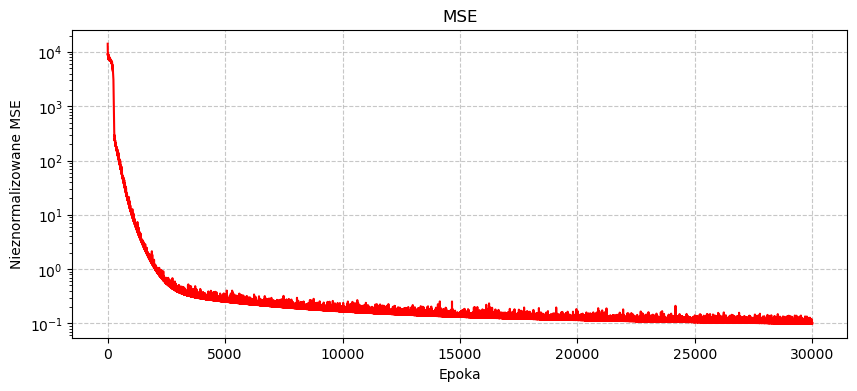

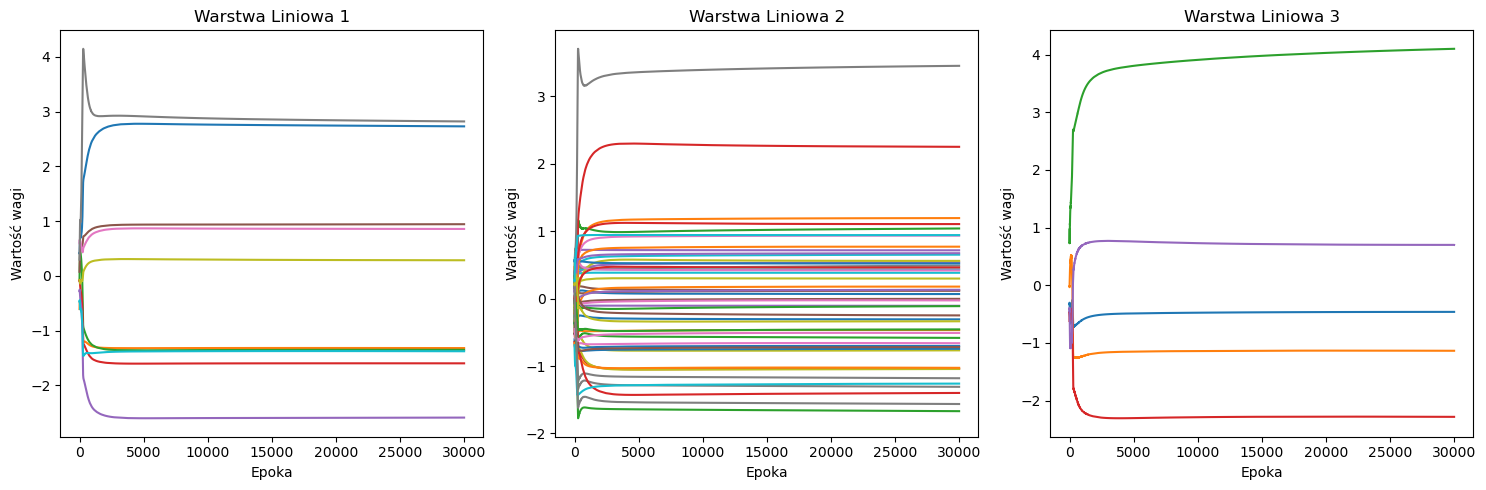

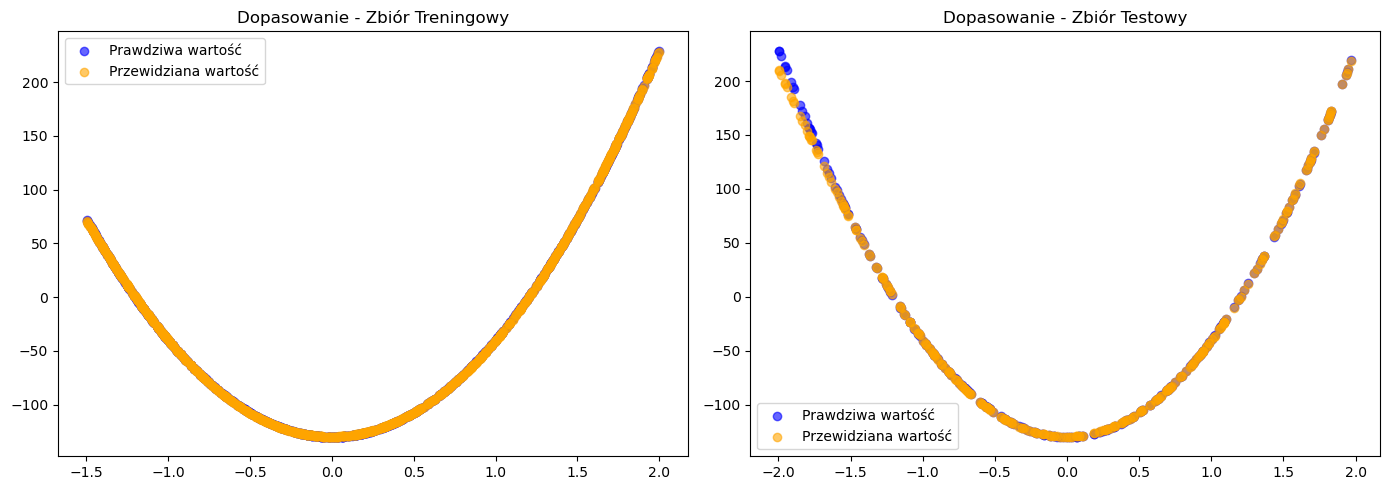

In [123]:
moment_1 = train(X_train, y_train, X_test, y_test, model, 30000, 64, True)

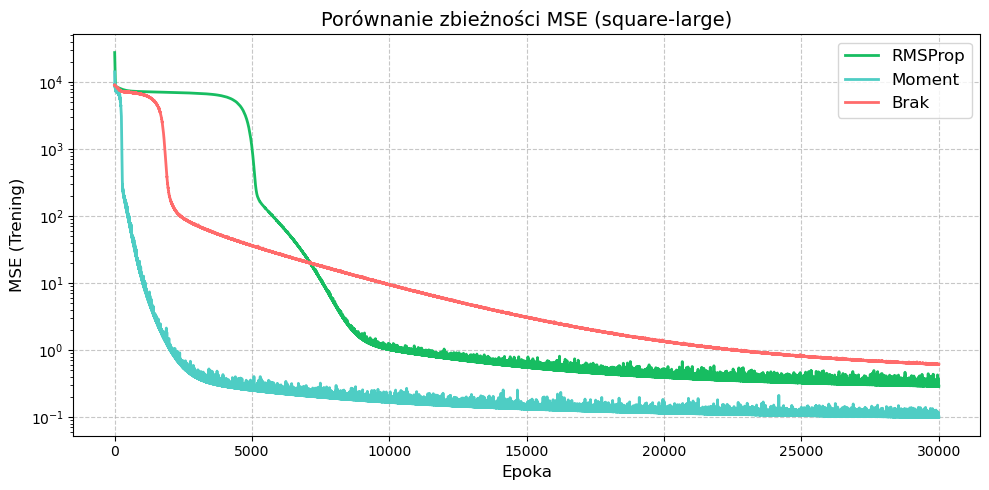

In [124]:
wykres_mse(brak_1, rmsprop_1, moment_1, 'square-large')

# Dane steps large

In [125]:
steps_large_test = pd.read_csv("mio1/regression/steps-large-test.csv")
steps_large_train = pd.read_csv("mio1/regression/steps-large-training.csv")
X_train = steps_large_train[['x']].to_numpy()
y_train = steps_large_train[['y']].to_numpy()
X_test = steps_large_test[['x']].to_numpy()
y_test = steps_large_test[['y']].to_numpy()

In [126]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.8)

Krok     0 | MSE Trening: 1480.9602
Krok  1000 | MSE Trening: 374.8939
Krok  2000 | MSE Trening: 309.5856
Krok  3000 | MSE Trening: 158.0321
Krok  4000 | MSE Trening: 128.2366
Krok  5000 | MSE Trening: 119.3153
Krok  6000 | MSE Trening: 111.2603
Krok  7000 | MSE Trening: 107.1259
Krok  8000 | MSE Trening: 101.4897
Krok  9000 | MSE Trening:  97.7177
Krok 10000 | MSE Trening: 184.0756
Krok 11000 | MSE Trening:  65.4799
Krok 12000 | MSE Trening:  80.0714
Krok 13000 | MSE Trening:  57.1991
Krok 14000 | MSE Trening:  57.3144
Krok 15000 | MSE Trening:  53.2589
Krok 16000 | MSE Trening:  47.6748
Krok 17000 | MSE Trening:  47.1276
--------------------------------------------------
MSE treningowe FINALNE: 43.9199164361455
MSE testowe FINALNE: 43.67222948426517


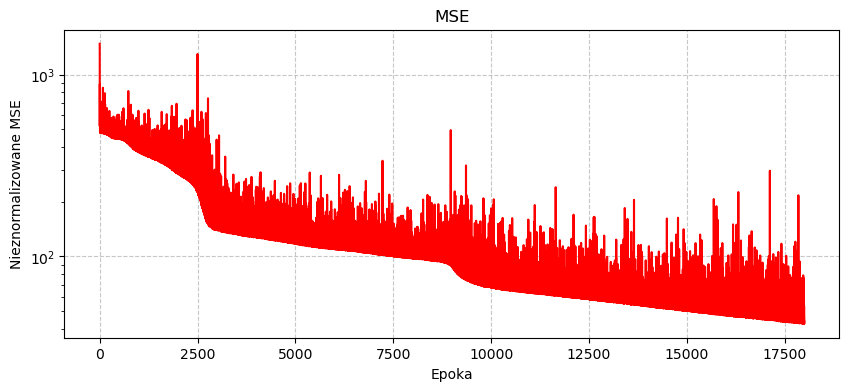

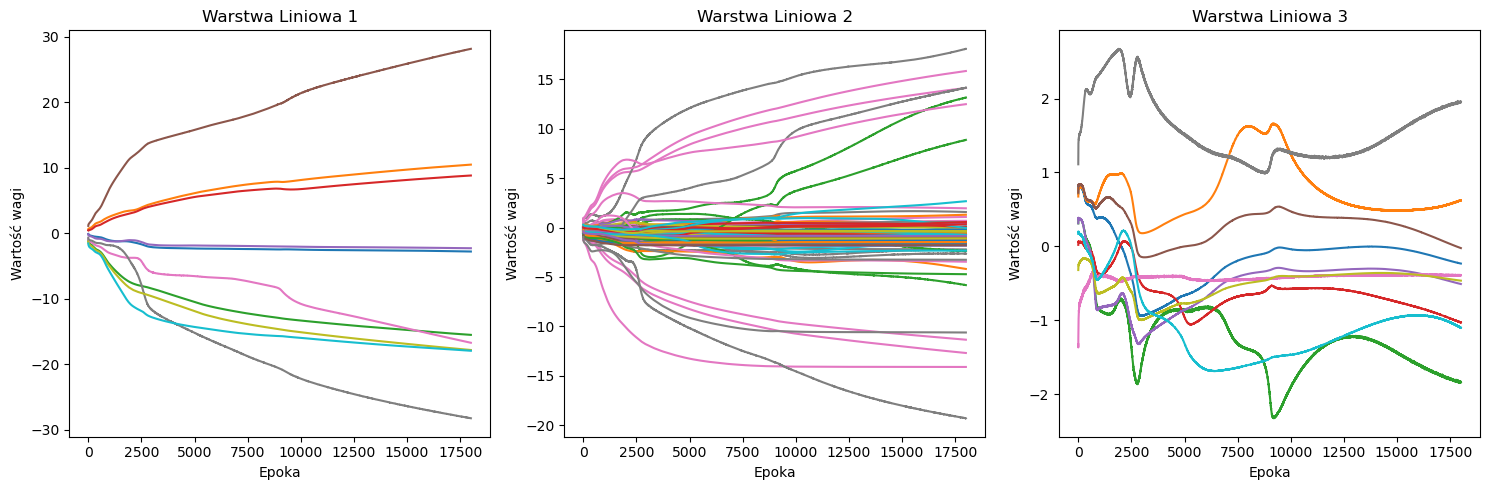

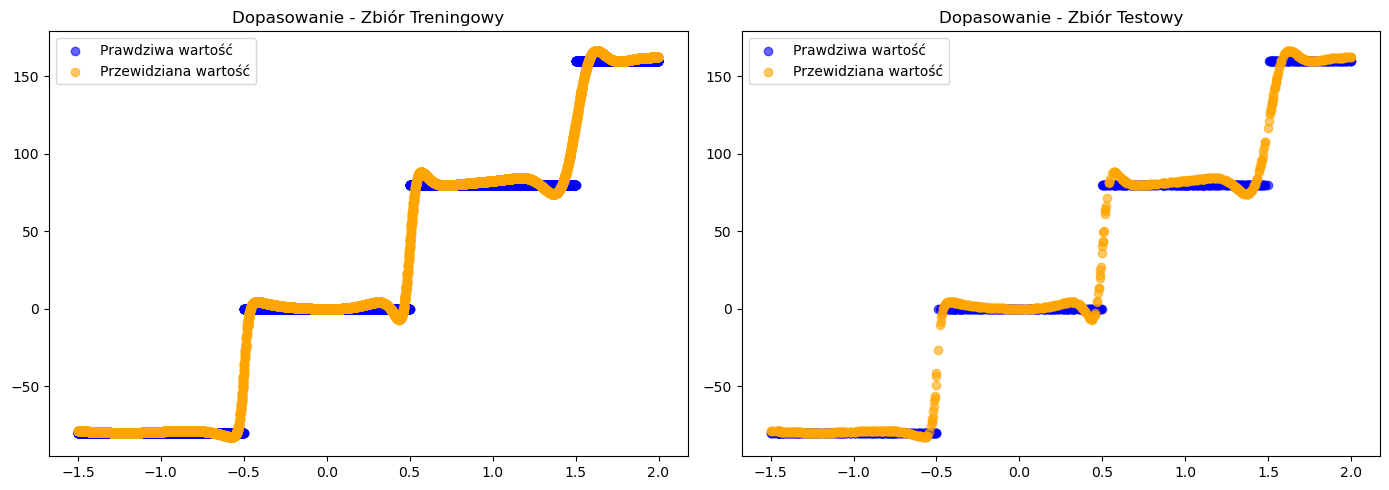

In [127]:
brak_2 = train(X_train, y_train, X_test, y_test, model, 18000, 32, True)

In [128]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.001, optymalizacja='RMSProp', wspolczynnik=0.9)

Krok     0 | MSE Trening: 5515.9200
Krok  1000 | MSE Trening: 378.7582
Krok  2000 | MSE Trening:  93.7714
Krok  3000 | MSE Trening:  62.4265
Krok  4000 | MSE Trening:  44.9490
Krok  5000 | MSE Trening:  38.1939
Krok  6000 | MSE Trening:  31.9635
Krok  7000 | MSE Trening:  30.8388
Krok  8000 | MSE Trening:  30.7090
Krok  9000 | MSE Trening:  25.1873
Krok 10000 | MSE Trening:  23.7814
Krok 11000 | MSE Trening:  26.5426
Krok 12000 | MSE Trening:  22.1183
Krok 13000 | MSE Trening:  22.8783
Krok 14000 | MSE Trening:  20.8883
Krok 15000 | MSE Trening:  20.7165
Krok 16000 | MSE Trening:  18.4434
Krok 17000 | MSE Trening:  19.4391
--------------------------------------------------
MSE treningowe FINALNE: 18.402427313177483
MSE testowe FINALNE: 17.505897002975956


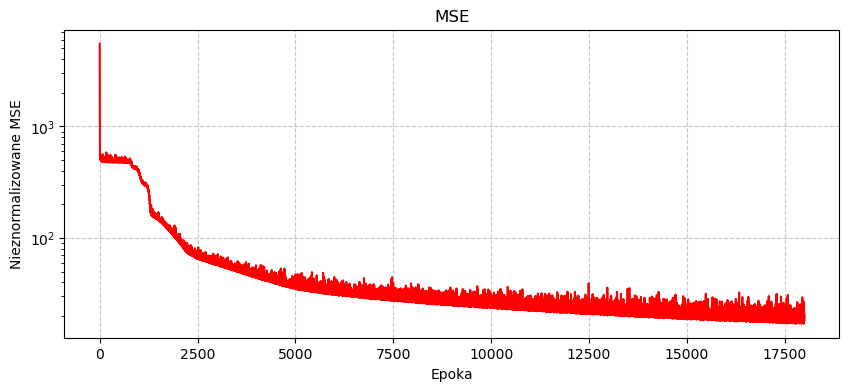

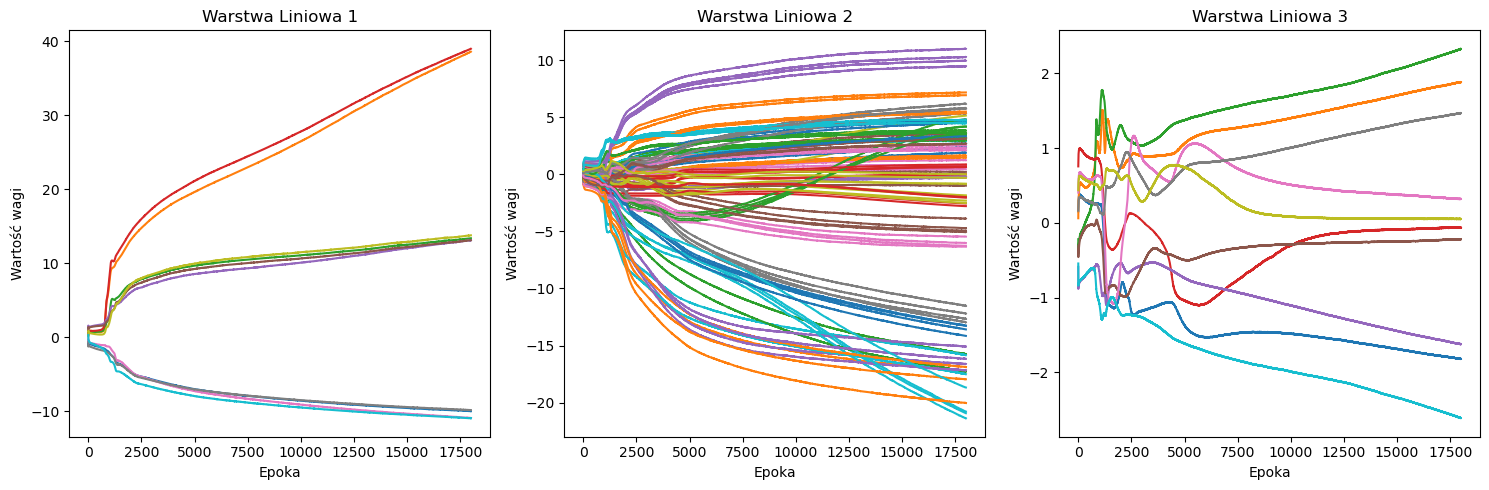

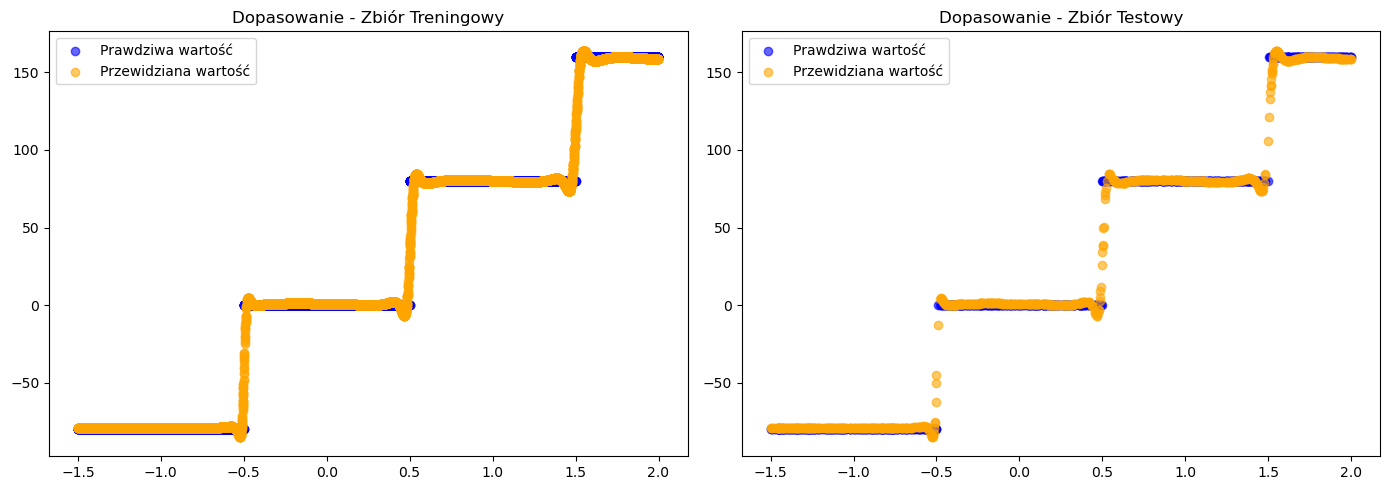

In [129]:
rmsprop_2 = train(X_train, y_train, X_test, y_test, model, 18000, 32, True)

In [130]:
warstwa_1 = warstwa_liniowa(1, 10, 'xavier')
warstwa_2 = warstwa_liniowa(10, 10, 'xavier')
warstwa_3 = warstwa_liniowa(10, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | MSE Trening: 642.9805
Krok  1000 | MSE Trening: 320.7083
Krok  2000 | MSE Trening: 134.9837
Krok  3000 | MSE Trening:  95.8069
Krok  4000 | MSE Trening:  74.7828
Krok  5000 | MSE Trening:  66.8264
Krok  6000 | MSE Trening:  56.0342
Krok  7000 | MSE Trening:  49.8829
Krok  8000 | MSE Trening:  45.7914
Krok  9000 | MSE Trening:  44.0568
Krok 10000 | MSE Trening:  40.5959
Krok 11000 | MSE Trening:  36.7686
Krok 12000 | MSE Trening:  33.8578
Krok 13000 | MSE Trening:  33.9208
Krok 14000 | MSE Trening:  30.3289
Krok 15000 | MSE Trening:  32.6049
Krok 16000 | MSE Trening:  28.7564
Krok 17000 | MSE Trening:  27.6239
--------------------------------------------------
MSE treningowe FINALNE: 27.023637176525448
MSE testowe FINALNE: 23.238600404078586


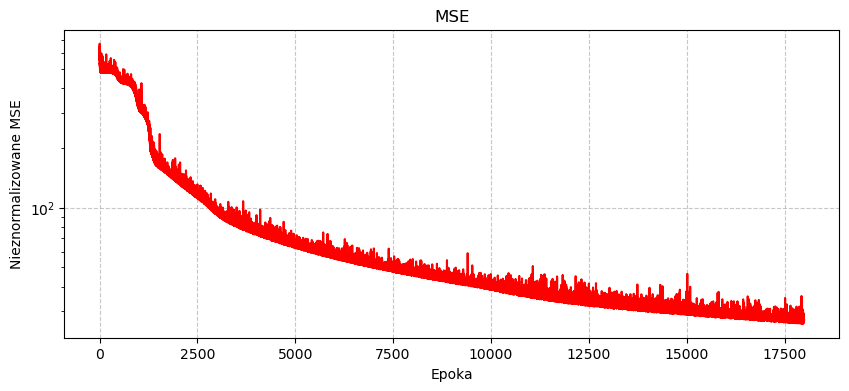

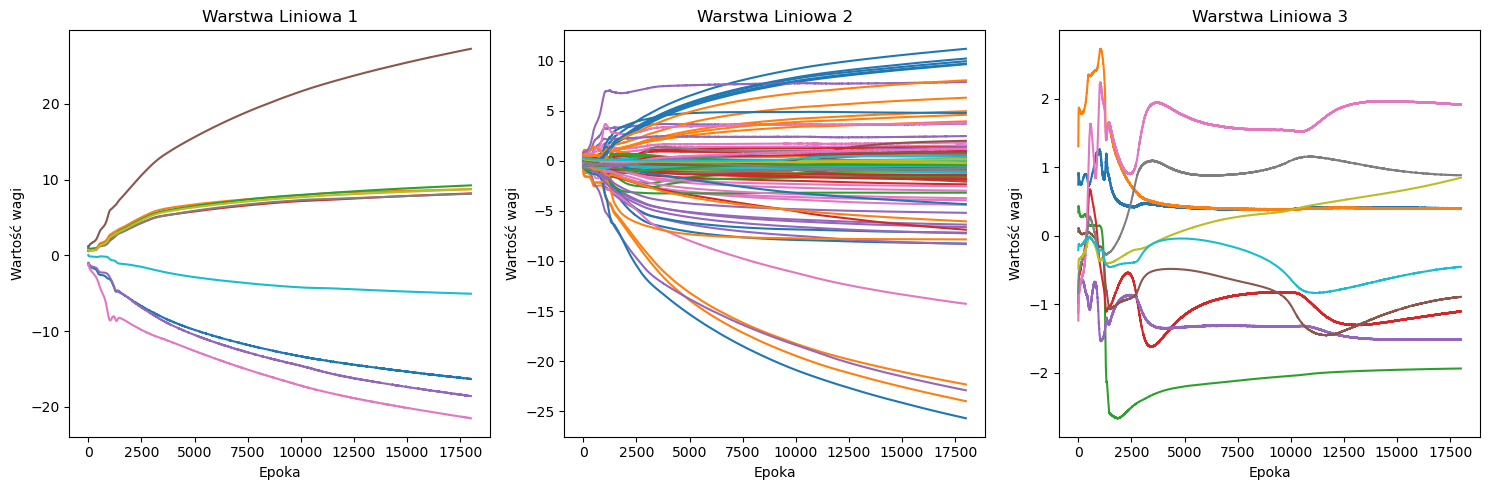

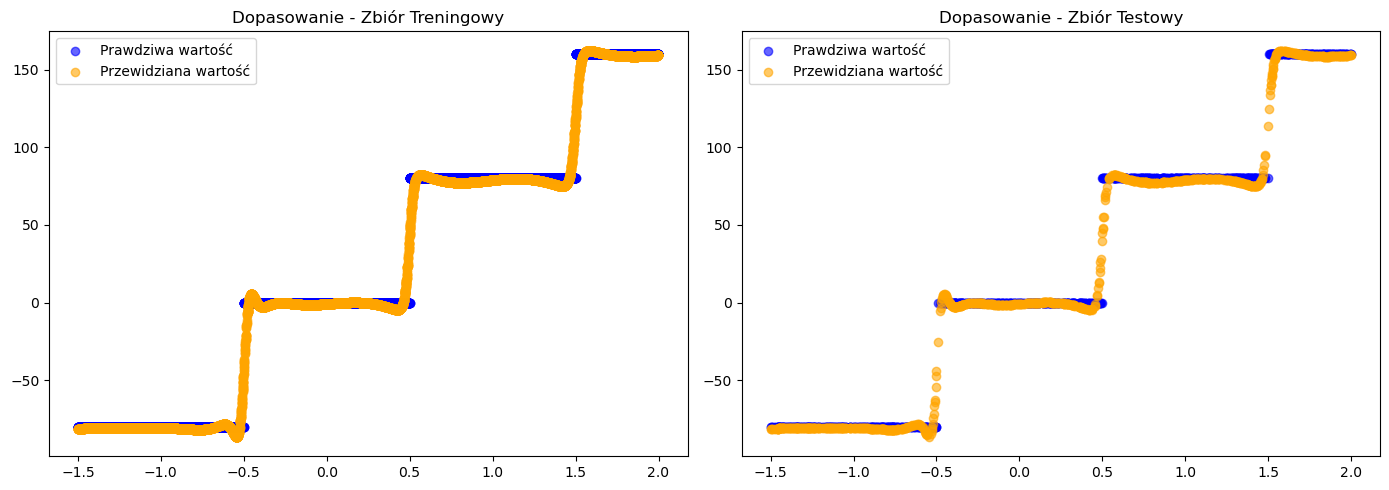

In [131]:
moment_2 = train(X_train, y_train, X_test, y_test, model, 18000, 32, True)

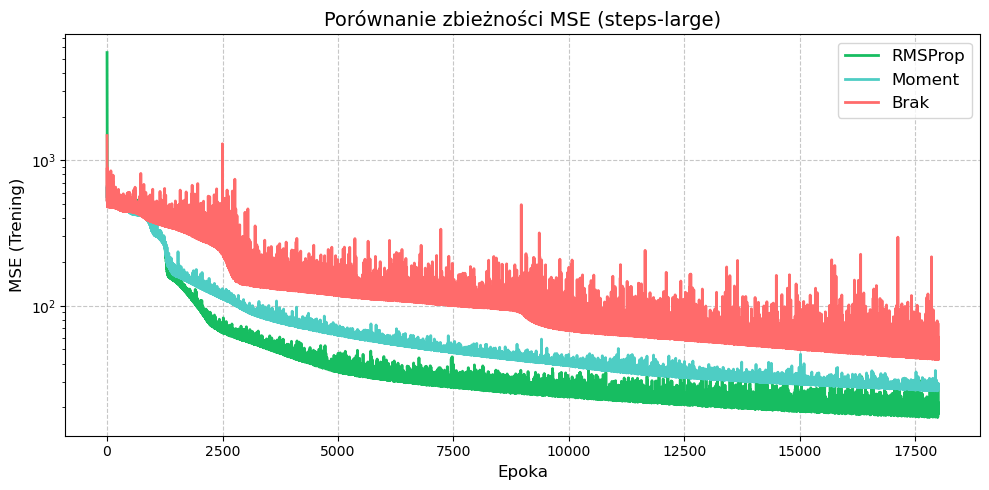

In [132]:
wykres_mse(brak_2, rmsprop_2, moment_2, 'steps-large')

# Dane multimodal large

In [133]:
multimodal_large_test = pd.read_csv("mio1/regression/multimodal-large-test.csv")
multimodal_large_train = pd.read_csv("mio1/regression/multimodal-large-training.csv")
X_train = multimodal_large_train[['x']].to_numpy()
y_train = multimodal_large_train[['y']].to_numpy()
X_test = multimodal_large_test[['x']].to_numpy()
y_test = multimodal_large_test[['y']].to_numpy()

In [134]:
warstwa_1 = warstwa_liniowa(1, 12, 'xavier')
warstwa_2 = warstwa_liniowa(12, 12, 'xavier')
warstwa_3 = warstwa_liniowa(12, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.3)

Krok     0 | MSE Trening: 5133.1512
Krok  1000 | MSE Trening: 323.2560
Krok  2000 | MSE Trening: 260.5789
Krok  3000 | MSE Trening: 130.9193
Krok  4000 | MSE Trening:  94.5659
Krok  5000 | MSE Trening:  99.6847
Krok  6000 | MSE Trening:  91.6882
Krok  7000 | MSE Trening:  75.2968
Krok  8000 | MSE Trening:  74.1355
Krok  9000 | MSE Trening:  68.1609
Krok 10000 | MSE Trening:  62.4593
Krok 11000 | MSE Trening:  54.8951
Krok 12000 | MSE Trening:  42.7993
Krok 13000 | MSE Trening:  27.6674
Krok 14000 | MSE Trening:  15.9739
--------------------------------------------------
MSE treningowe FINALNE: 13.18175692560235
MSE testowe FINALNE: 9.976836040549628


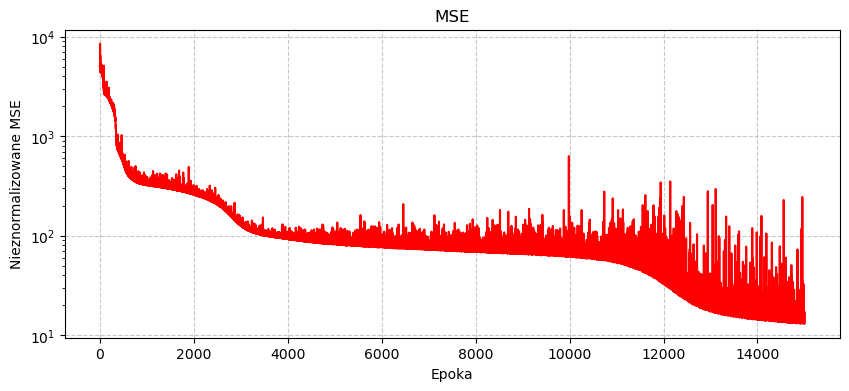

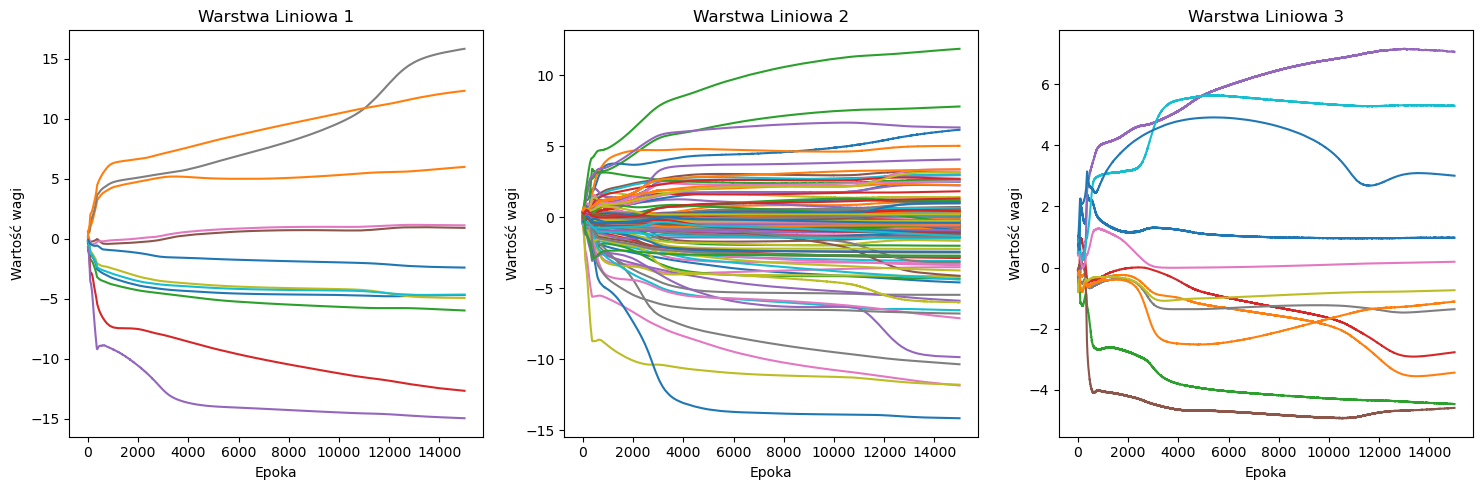

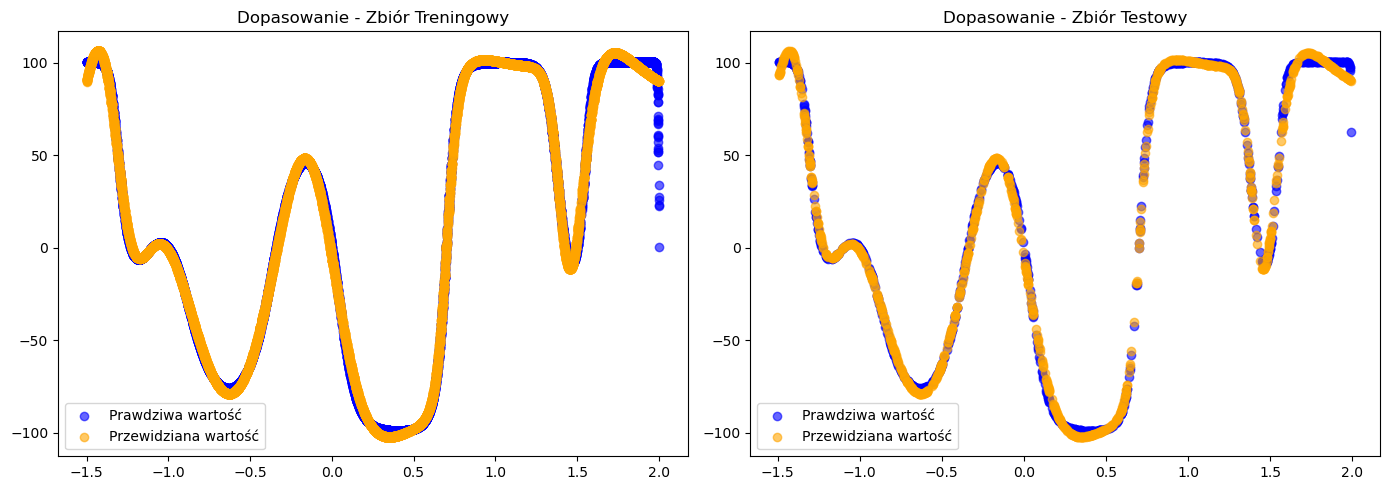

In [135]:
brak_3 = train(X_train, y_train, X_test, y_test, model, 15000, 64, True)

In [136]:
warstwa_1 = warstwa_liniowa(1, 12, 'xavier')
warstwa_2 = warstwa_liniowa(12, 12, 'xavier')
warstwa_3 = warstwa_liniowa(12, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.001, optymalizacja='RMSProp', wspolczynnik=0.9)

Krok     0 | MSE Trening: 5178.6947
Krok  1000 | MSE Trening: 546.9421
Krok  2000 | MSE Trening: 180.1034
Krok  3000 | MSE Trening:  34.9233
Krok  4000 | MSE Trening:  22.0322
Krok  5000 | MSE Trening:  11.5904
Krok  6000 | MSE Trening:   8.9141
Krok  7000 | MSE Trening:  10.0703
Krok  8000 | MSE Trening:   7.6982
Krok  9000 | MSE Trening:   8.4011
Krok 10000 | MSE Trening:   8.0889
Krok 11000 | MSE Trening:   8.2593
Krok 12000 | MSE Trening:   7.3715
Krok 13000 | MSE Trening:   8.7727
Krok 14000 | MSE Trening:   8.2202
--------------------------------------------------
MSE treningowe FINALNE: 8.553611165330867
MSE testowe FINALNE: 5.217714225071375


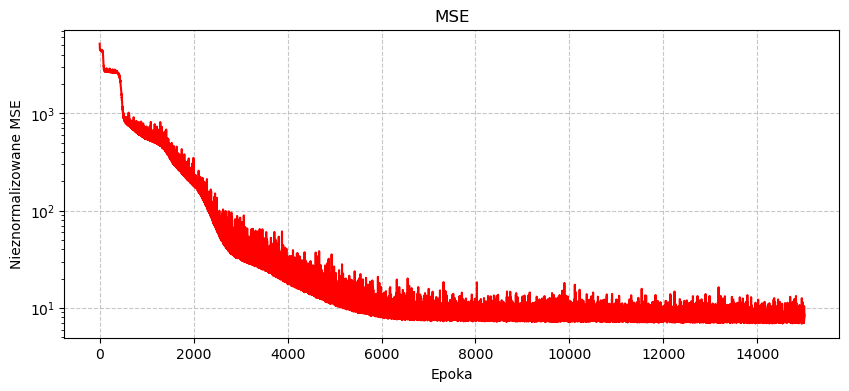

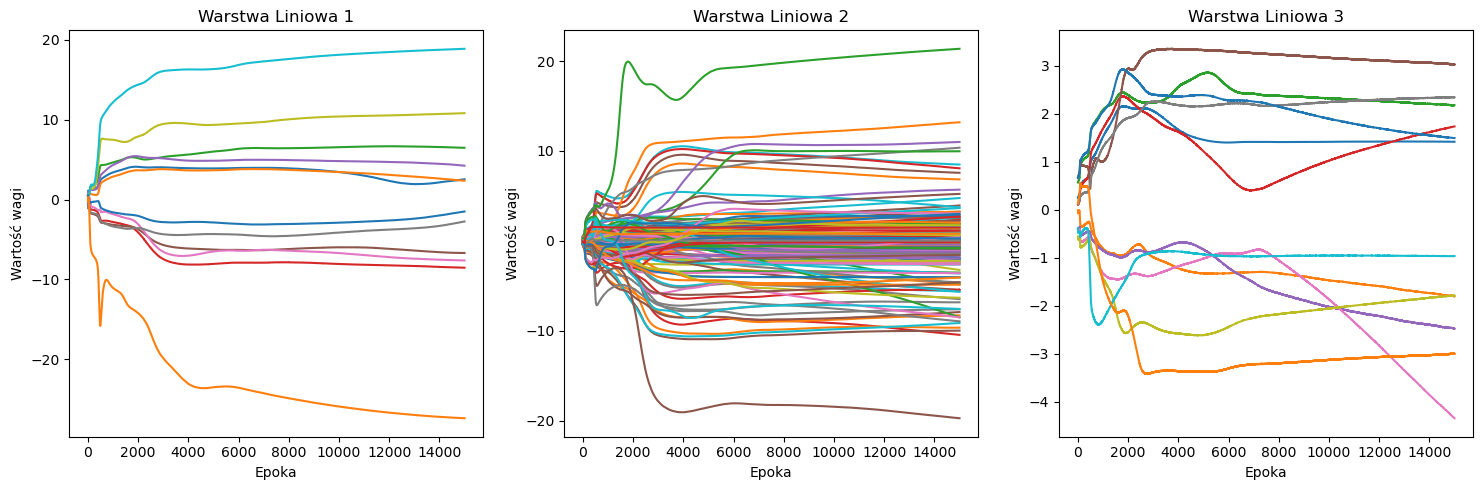

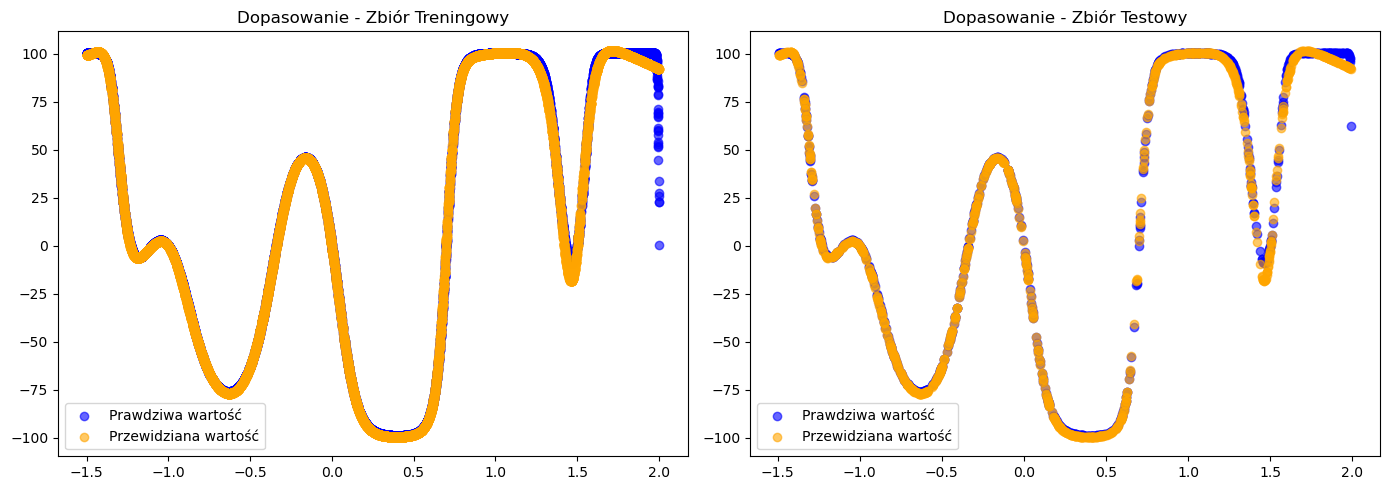

In [137]:
rmsprop_3 = train(X_train, y_train, X_test, y_test, model, 15000, 64, True)

In [138]:
warstwa_1 = warstwa_liniowa(1, 12, 'xavier')
warstwa_2 = warstwa_liniowa(12, 12, 'xavier')
warstwa_3 = warstwa_liniowa(12, 1, 'xavier')
model = MLP((warstwa_1, sigmoid(), warstwa_2, sigmoid(), warstwa_3), learning_rate=0.1, optymalizacja='moment', wspolczynnik=0.9)

Krok     0 | MSE Trening: 4717.9853
Krok  1000 | MSE Trening: 210.2640
Krok  2000 | MSE Trening:  83.1254
Krok  3000 | MSE Trening:  70.1429
Krok  4000 | MSE Trening:  66.8515
Krok  5000 | MSE Trening:  48.8997
Krok  6000 | MSE Trening:  15.3580
Krok  7000 | MSE Trening:   9.8656
Krok  8000 | MSE Trening:   9.7670
Krok  9000 | MSE Trening:   9.0058
Krok 10000 | MSE Trening:   9.0049
Krok 11000 | MSE Trening:   9.6246
Krok 12000 | MSE Trening:  10.9907
Krok 13000 | MSE Trening:   8.9198
Krok 14000 | MSE Trening:   8.5961
--------------------------------------------------
MSE treningowe FINALNE: 9.697935015394101
MSE testowe FINALNE: 6.298060946412214


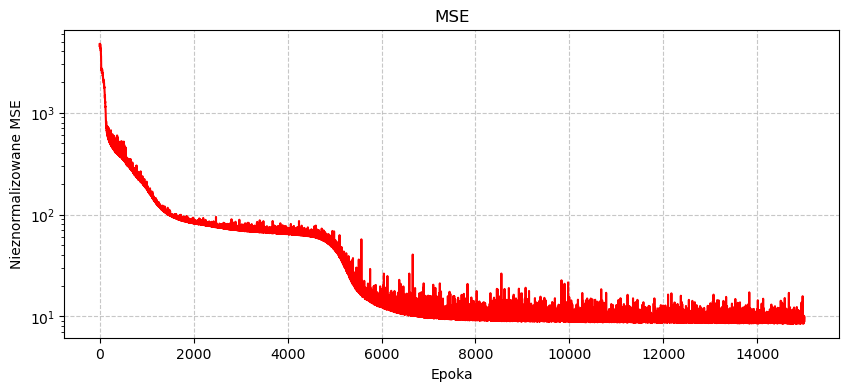

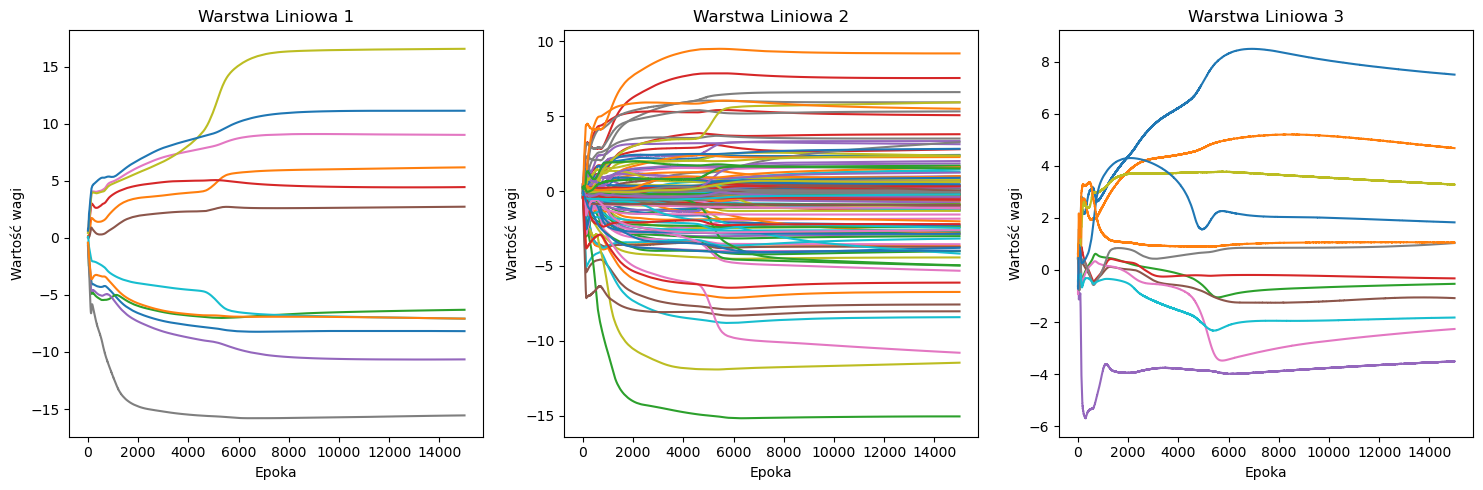

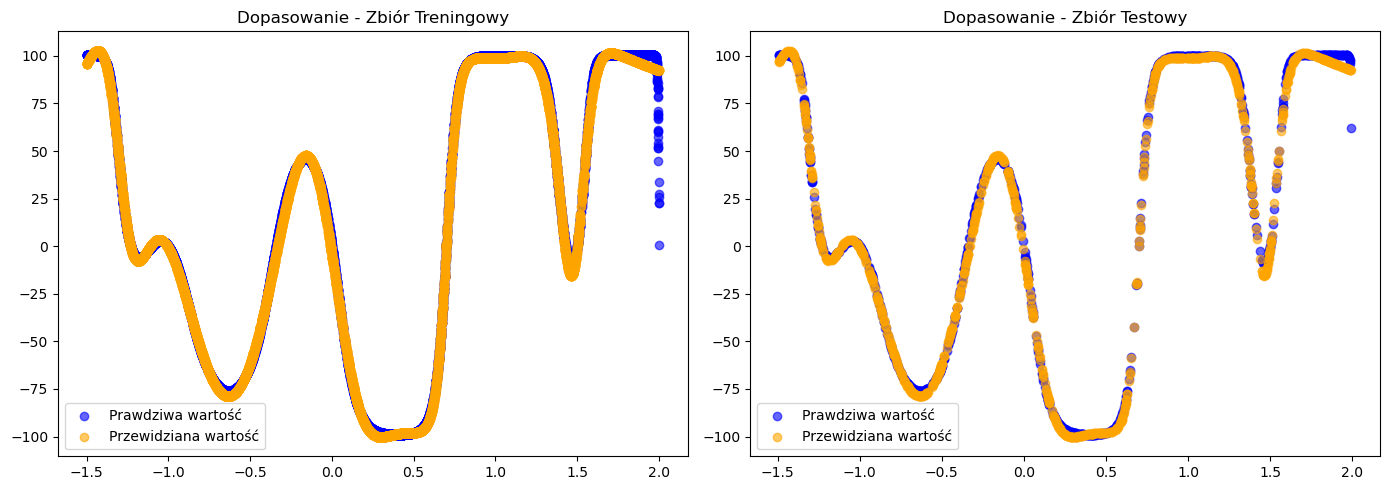

In [139]:
moment_3 = train(X_train, y_train, X_test, y_test, model, 15000, 64, True)

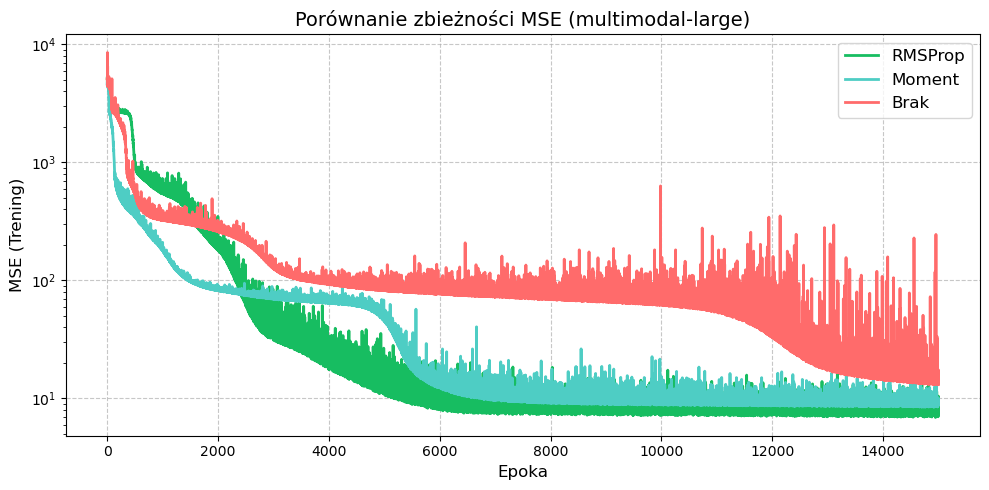

In [140]:
wykres_mse(brak_3, rmsprop_3, moment_3, 'multimodal-large')